## Data Mining Assignment 2
### Build a Recommender System using a Medallion Data Lake


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timezone
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
import requests
import zipfile

In [2]:
folders = ["bronze", "silver", "gold"]
for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Data Lake folders:")
for folder in folders:
    print(f"{folder}/")

Data Lake folders:
bronze/
silver/
gold/


In [3]:
dataset_url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
response = requests.get(dataset_url)
response.raise_for_status()

In [4]:
with open("book-crossings.zip", "wb") as file:
    file.write(response.content)

with zipfile.ZipFile("book-crossings.zip", "r") as zip_ref:
    zip_ref.extractall("raw_data")
print(os.listdir("raw_data"))

['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


In [5]:
users_raw = pd.read_csv(
    "raw_data/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    escapechar="\\"
)

books_raw = pd.read_csv(
    "raw_data/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    escapechar="\\"
)

ratings_raw = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    escapechar="\\"
)

print("Users:", users_raw.shape)
print("Books:", books_raw.shape)
print("Ratings:", ratings_raw.shape)

Users: (278858, 3)
Books: (271379, 8)
Ratings: (1149780, 3)


In [6]:
ingestion_time = datetime.now(timezone.utc)
users_bronze = users_raw.copy()
books_bronze = books_raw.copy()
ratings_bronze = ratings_raw.copy()

users_bronze["ingestion_timestamp"] = ingestion_time
books_bronze["ingestion_timestamp"] = ingestion_time
ratings_bronze["ingestion_timestamp"] = ingestion_time

In [7]:
users_bronze.to_parquet("bronze/users.parquet", index=False)
books_bronze.to_parquet("bronze/books.parquet", index=False)
ratings_bronze.to_parquet("bronze/ratings.parquet", index=False)
print("Bronze layer is created")
print(os.listdir("bronze"))

Bronze layer is created
['ratings.parquet', 'books.parquet', 'users.parquet']


In [8]:
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")
print("Bronze layer datasets:")
print("\nUsers:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Bronze layer datasets:

Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [9]:
datasets = {
    "Users": users,
    "Books": books,
    "Ratings": ratings
}

for name, df in datasets.items():
    print(f"{name.upper()} DATASET")
    print("\nShape:", df.shape)
    print("\nData Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\n")
    print("\n")

USERS DATASET

Shape: (278858, 4)

Data Types:
User-ID                             object
Location                            object
Age                                 object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64




BOOKS DATASET

Shape: (271379, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                 object
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            

Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Number of zero ratings: 716109
Number of explicit ratings: 433671


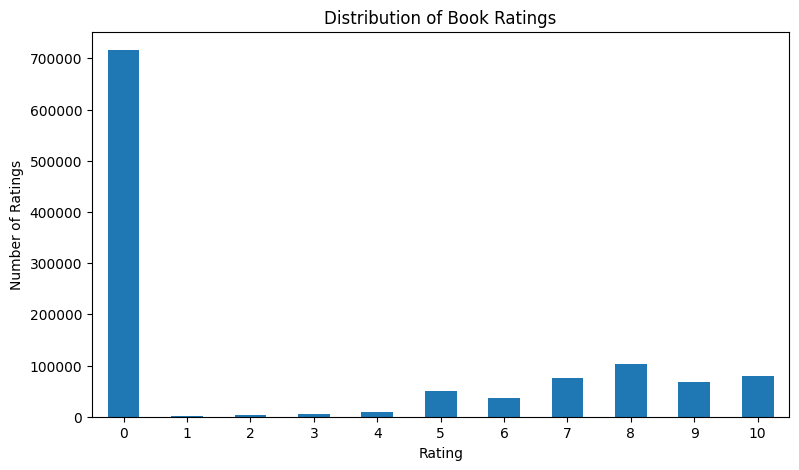

In [10]:
ratings["Book-Rating"] = pd.to_numeric(ratings["Book-Rating"], errors="coerce")
rating_counts = ratings["Book-Rating"].value_counts().sort_index()
print("Rating Distribution:")
print(rating_counts)
print("\nNumber of zero ratings:", (ratings["Book-Rating"] == 0).sum())
print("Number of explicit ratings:",
      ((ratings["Book-Rating"] >= 1) &
       (ratings["Book-Rating"] <= 10)).sum())

plt.figure(figsize=(9, 5))
rating_counts.plot(kind="bar")
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.show()

Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Missing ages: 110762
Ages below 5: 882
Ages above 100: 366


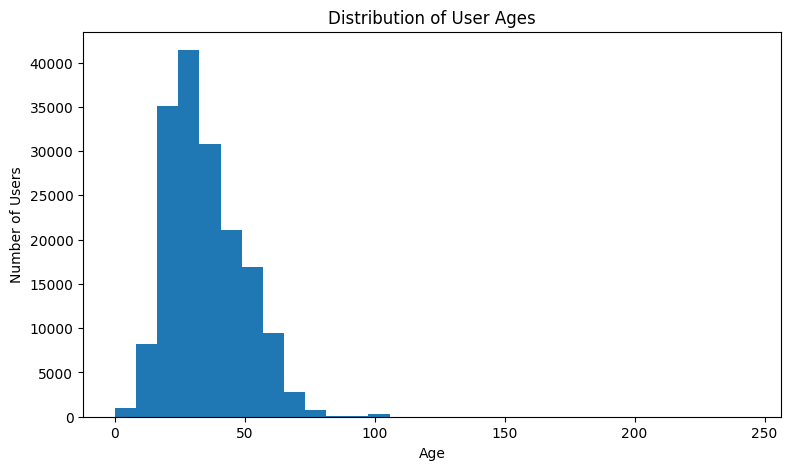

In [11]:
users["Age"] = pd.to_numeric(users["Age"], errors="coerce")
print("Age Statistics:")
print(users["Age"].describe())
print("\nMissing ages:", users["Age"].isnull().sum())
print("Ages below 5:", (users["Age"] < 5).sum())
print("Ages above 100:", (users["Age"] > 100).sum())
plt.figure(figsize=(9, 5))
users["Age"].dropna().plot(kind="hist", bins=30)
plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()

Publication Year Statistics:
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Year equal to zero: 4619
Future publication years: 11


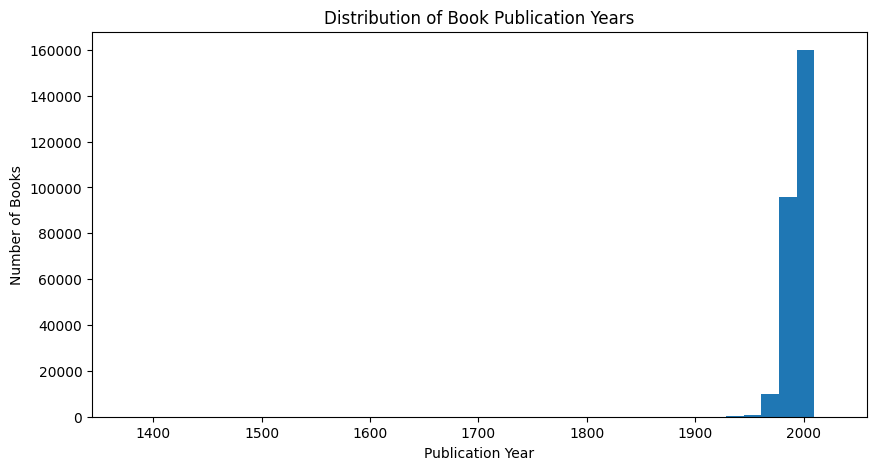

In [12]:
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)
print("Publication Year Statistics:")
print(books["Year-Of-Publication"].describe())

current_year = datetime.now().year

print("\nYear equal to zero:",
      (books["Year-Of-Publication"] == 0).sum())

print("Future publication years:",
      (books["Year-Of-Publication"] > current_year).sum())

valid_years = books[
    (books["Year-Of-Publication"] > 0) &
    (books["Year-Of-Publication"] <= current_year)
]

plt.figure(figsize=(10, 5))
valid_years["Year-Of-Publication"].plot(kind="hist", bins=40)
plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.show()

Ratings per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


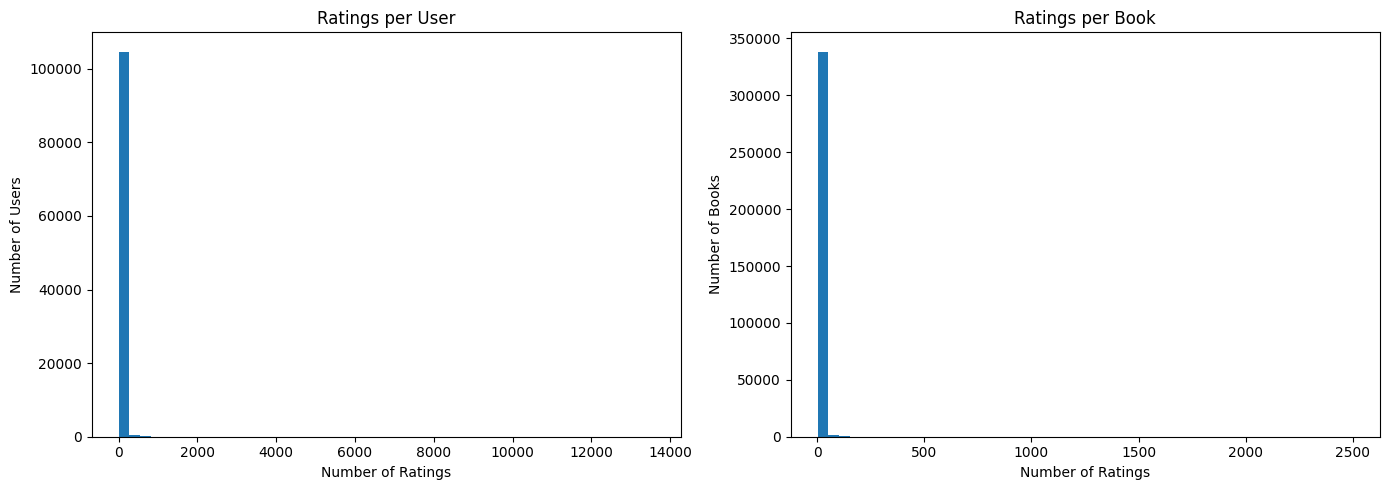

In [13]:
ratings_per_user = ratings.groupby("User-ID").size()
ratings_per_book = ratings.groupby("ISBN").size()
print("Ratings per User:")
print(ratings_per_user.describe())
print("\nRatings per Book:")
print(ratings_per_book.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(ratings_per_user, bins=50)
axes[0].set_title("Ratings per User")
axes[0].set_xlabel("Number of Ratings")
axes[0].set_ylabel("Number of Users")
axes[1].hist(ratings_per_book, bins=50)
axes[1].set_title("Ratings per Book")
axes[1].set_xlabel("Number of Ratings")
axes[1].set_ylabel("Number of Books")
plt.tight_layout()
plt.show()

In [14]:
total_users = ratings["User-ID"].nunique()
total_books = ratings["ISBN"].nunique()
rated_pairs = ratings[["User-ID", "ISBN"]].drop_duplicates().shape[0]
total_possible_pairs = total_users * total_books
sparsity = (1-rated_pairs/total_possible_pairs)*100

print("Unique Users:", total_users)
print("Unique Books:", total_books)
print("Distinct Rated User-Book Pairs:", rated_pairs)
print("Total Possible User-Book Pairs:", total_possible_pairs)
print(f"Matrix Sparsity: {sparsity:.4f}%")
print(f"Matrix Density: {100-sparsity:.4f}%")

Unique Users: 105283
Unique Books: 340556
Distinct Rated User-Book Pairs: 1149780
Total Possible User-Book Pairs: 35854757348
Matrix Sparsity: 99.9968%
Matrix Density: 0.0032%



## EDA Observations and Silver Layer Preparation

The initial exploratory analysis revealed the following characteristics and data quality issues across the three datasets:

1. **Dataset structure and missing values:** The Users dataset contains 278,858 records, Books contains 271,379 records, and Ratings contains 1,149,780 records. The Users dataset has 110,762 missing ages, while Books contains 2 missing authors and 2 missing publishers. These fields require appropriate cleaning and imputation.

2. **Rating distribution:** Out of 1,149,780 ratings, 716,109 are implicit ratings (0), while 433,671 are explicit ratings ranging from 1 to 10. The Silver layer will retain only explicit ratings for collaborative filtering.

3. **User age quality:** The age distribution contains 882 values below 5 and 366 values above 100. Missing and unrealistic ages will be handled using median imputation after identifying invalid values.

4. **Publication year quality:** The Books dataset contains 4,619 entries with publication year 0 and 11 future publication years. These values will be treated as invalid and converted to missing values.

5. **Rating activity:** The number of ratings varies considerably across users and books. Many users and books have very few interactions, which can affect the reliability of collaborative filtering recommendations.

6. **Matrix sparsity:** The original user-book interaction matrix has approximately 99.9968% sparsity, indicating that only a very small proportion of possible user-book combinations have ratings.

7. **Planned preprocessing:** The Silver layer will include duplicate removal, rating validation, age cleaning, location extraction, publication year validation, text standardization, and filtering of users and books with insufficient rating activity.

In [15]:
users_silver = pd.read_parquet("bronze/users.parquet")
books_silver = pd.read_parquet("bronze/books.parquet")
ratings_silver = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets for Silver processing")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

Bronze datasets for Silver processing
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [16]:
print("Duplicates before cleaning:")
print("Users:", users_silver.duplicated(subset=["User-ID"]).sum())
print("Books:", books_silver.duplicated(subset=["ISBN"]).sum())
print("Ratings:", ratings_silver.duplicated().sum())

users_silver = users_silver.drop_duplicates(subset=["User-ID"], keep="first")
books_silver = books_silver.drop_duplicates(subset=["ISBN"], keep="first")
ratings_silver = ratings_silver.drop_duplicates()

print("\nAfter removing duplicates:")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

Duplicates before cleaning:
Users: 0
Books: 0
Ratings: 0

After removing duplicates:
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [17]:
ratings_silver["Book-Rating"] = pd.to_numeric(
    ratings_silver["Book-Rating"], errors="coerce"
)
ratings_silver = ratings_silver[
    ratings_silver["Book-Rating"].between(1, 10)
].copy()
print("Ratings after removing zero and invalid ratings:", ratings_silver.shape)
print("\nRating distribution after cleaning:")
print(ratings_silver["Book-Rating"].value_counts().sort_index())

Ratings after removing zero and invalid ratings: (433671, 4)

Rating distribution after cleaning:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


In [18]:
users_silver["Age"] = pd.to_numeric(users_silver["Age"], errors="coerce")
users_silver.loc[
    (users_silver["Age"] < 5) | (users_silver["Age"] > 100),
    "Age"
] = np.nan
median_age = users_silver["Age"].median()
users_silver["Age"] = users_silver["Age"].fillna(median_age)
print("Median age used:", median_age)
print("Missing ages after cleaning:", users_silver["Age"].isnull().sum())
print("\nAge statistics after cleaning:")
print(users_silver["Age"].describe())

Median age used: 32.0
Missing ages after cleaning: 0

Age statistics after cleaning:
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64


In [19]:
location_parts = (
    users_silver["Location"]
    .fillna("")
    .astype(str)
    .str.split(",", n=2, expand=True)
)

for i in range(3):
    if i not in location_parts.columns:
        location_parts[i] = np.nan

users_silver["City"] = location_parts[0].fillna("").str.strip().str.title()
users_silver["State"] = location_parts[1].fillna("").str.strip().str.title()
users_silver["Country"] = location_parts[2].fillna("").str.strip().str.title()
users_silver = users_silver.drop(columns=["Location"])
print(users_silver[["City", "State", "Country"]].head())

          City            State         Country
0          Nyc         New York             Usa
1     Stockton       California             Usa
2       Moscow  Yukon Territory          Russia
3        Porto         V.N.Gaia        Portugal
4  Farnborough            Hants  United Kingdom


In [20]:
books_silver["Year-Of-Publication"] = pd.to_numeric(
    books_silver["Year-Of-Publication"],
    errors="coerce"
)

current_year = datetime.now().year

books_silver.loc[
    (books_silver["Year-Of-Publication"] == 0) |
    (books_silver["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

books_silver["Year-Of-Publication"] = (
    books_silver["Year-Of-Publication"].astype("Int64")
)
print("Invalid publication years remaining:",
      ((books_silver["Year-Of-Publication"] == 0) |
       (books_silver["Year-Of-Publication"] > current_year)).sum())
print("\nMissing publication years:",
      books_silver["Year-Of-Publication"].isnull().sum())

Invalid publication years remaining: 0

Missing publication years: 4630


In [21]:
text_columns = ["Book-Title", "Book-Author", "Publisher"]

for col in text_columns:
    books_silver[col] = (
        books_silver[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )
books_silver["ISBN"] = books_silver["ISBN"].astype(str).str.strip()
books_silver = books_silver.drop(
    columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"]
)
for col in ["City", "State", "Country"]:
    users_silver[col] = (
        users_silver[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )
print("Text cleaning completed.")
print("\nBook columns:")
print(books_silver.columns.tolist())
print("\nUser columns:")
print(users_silver.columns.tolist())

Text cleaning completed.

Book columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'ingestion_timestamp']

User columns:
['User-ID', 'Age', 'ingestion_timestamp', 'City', 'State', 'Country']


In [22]:
valid_user_ids = set(users_silver["User-ID"])
valid_book_ids = set(books_silver["ISBN"])
ratings_silver = ratings_silver[
    ratings_silver["User-ID"].isin(valid_user_ids) &
    ratings_silver["ISBN"].isin(valid_book_ids)
].copy()
print("Ratings after validating user and book IDs:", ratings_silver.shape)

Ratings after validating user and book IDs: (383852, 4)


In [23]:
min_ratings = 10
previous_shape = None
while previous_shape != ratings_silver.shape:
    previous_shape = ratings_silver.shape
    user_counts = ratings_silver["User-ID"].value_counts()
    book_counts = ratings_silver["ISBN"].value_counts()
    valid_users = user_counts[user_counts >= min_ratings].index
    valid_books = book_counts[book_counts >= min_ratings].index
    ratings_silver = ratings_silver[
        ratings_silver["User-ID"].isin(valid_users) &
        ratings_silver["ISBN"].isin(valid_books)
    ].copy()

print("Threshold filtering completed.")
print("Remaining ratings:", ratings_silver.shape[0])
print("Remaining users:", ratings_silver["User-ID"].nunique())
print("Remaining books:", ratings_silver["ISBN"].nunique())

Threshold filtering completed.
Remaining ratings: 41456
Remaining users: 1820
Remaining books: 2030


In [24]:
retained_users = ratings_silver["User-ID"].unique()
retained_books = ratings_silver["ISBN"].unique()
users_silver = users_silver[
    users_silver["User-ID"].isin(retained_users)
].copy()
books_silver = books_silver[
    books_silver["ISBN"].isin(retained_books)
].copy()
print("Final Silver dataset shapes:")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

Final Silver dataset shapes:
Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)


In [25]:
user_rating_counts = ratings_silver.groupby("User-ID").size()
book_rating_counts = ratings_silver.groupby("ISBN").size()
print("Minimum ratings by a user:", user_rating_counts.min())
print("Minimum ratings for a book:", book_rating_counts.min())
print("Users below threshold:", (user_rating_counts < min_ratings).sum())
print("Books below threshold:", (book_rating_counts < min_ratings).sum())

Minimum ratings by a user: 10
Minimum ratings for a book: 10
Users below threshold: 0
Books below threshold: 0


In [26]:
os.makedirs("silver", exist_ok=True)
users_silver.to_parquet("silver/users.parquet", index=False)
books_silver.to_parquet("silver/books.parquet", index=False)
ratings_silver.to_parquet("silver/ratings.parquet", index=False)
users_silver.to_csv("silver/users.csv", index=False)
books_silver.to_csv("silver/books.csv", index=False)
ratings_silver.to_csv("silver/ratings.csv", index=False)
print("Silver layer saved successfully!")
print(os.listdir("silver"))

Silver layer saved successfully!
['ratings.parquet', 'books.csv', 'ratings.csv', 'books.parquet', 'users.parquet', 'users.csv']


In [27]:
print("FINAL SILVER LAYER SUMMARY")
print("\nUsers:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)
print("\nMissing values:")
for name, df in {
    "Users": users_silver,
    "Books": books_silver,
    "Ratings": ratings_silver
}.items():
    print(f"\n{name}:")
    print(df.isnull().sum())
print("\nRating distribution:")
print(ratings_silver["Book-Rating"].value_counts().sort_index())

FINAL SILVER LAYER SUMMARY

Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)

Missing values:

Users:
User-ID                0
Age                    0
ingestion_timestamp    0
City                   0
State                  0
Country                0
dtype: int64

Books:
ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    4
Publisher              0
ingestion_timestamp    0
dtype: int64

Ratings:
User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64

Rating distribution:
Book-Rating
1       121
2       183
3       365
4       580
5      3508
6      2772
7      6440
8     10173
9      8000
10     9314
Name: count, dtype: int64



## Silver Layer Preprocessing Summary

The Silver layer was created by cleaning and standardizing the Bronze datasets through the following operations:

1. **Duplicate handling:** Checked for duplicate User IDs, ISBNs, and rating records. No duplicates were found in the initial datasets.

2. **Rating validation:** Converted book ratings into numeric values and retained only explicit ratings between 1 and 10, removing implicit zero ratings and invalid entries. This reduced the ratings dataset from 1,149,780 to 433,671 records.

3. **Age cleaning:** Converted age values into numeric format, replaced ages below 5 and above 100 with missing values, and imputed missing values using the median age of 32.

4. **Location processing:** Split the original Location field into City, State, and Country columns. Standardized text formatting and removed the original Location column.

5. **Publication year cleaning:** Converted publication years into numeric format and treated zero and future publication years as missing values. The resulting column was stored using a nullable integer type.

6. **Text standardization:** Handled missing book titles, authors, and publishers by replacing them with "Unknown". Removed unnecessary whitespace, standardized text formatting, and cleaned ISBN values.

7. **Column selection:** Removed the three book image URL columns, retaining only the fields required for the recommendation system.

8. **ID validation:** Retained rating records associated with valid users and books present in the cleaned datasets.

9. **Interaction filtering:** Applied an iterative minimum threshold of 10 ratings per user and 10 ratings per book. Repeated filtering ensured that both conditions remained satisfied after each filtering step.

10. **Final dataset:** The cleaned Silver layer contains:
    - Users: 1,820 records
    - Books: 2,030 records
    - Ratings: 41,456 records

11. **Validation and storage:** Verified the minimum rating threshold and checked missing values across all three datasets. No missing values remain in Users and Ratings, while 4 publication years remain missing in Books. The cleaned datasets were saved in both CSV and Parquet formats.


In [28]:
os.makedirs("gold", exist_ok=True)
users_silver = pd.read_parquet("silver/users.parquet")
books_silver = pd.read_parquet("silver/books.parquet")
ratings_silver = pd.read_parquet("silver/ratings.parquet")

print("Silver datasets loaded successfully.")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Silver datasets loaded successfully.
Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)


In [29]:
user_ids = ratings_silver["User-ID"].unique()
book_isbns = ratings_silver["ISBN"].unique()

user_to_index = {user_id: idx for idx, user_id in enumerate(user_ids)}
book_to_index = {isbn: idx for idx, isbn in enumerate(book_isbns)}

row_indices = ratings_silver["User-ID"].map(user_to_index).values
col_indices = ratings_silver["ISBN"].map(book_to_index).values
rating_values = ratings_silver["Book-Rating"].values

rating_matrix = csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(len(user_ids), len(book_isbns))
)
print("Sparse rating matrix created successfully!")
print("Matrix shape:", rating_matrix.shape)
print("Number of stored ratings:", rating_matrix.nnz)
print("Matrix density:", rating_matrix.nnz/(rating_matrix.shape[0]*rating_matrix.shape[1])*100,"%")

Sparse rating matrix created successfully!
Matrix shape: (1820, 2030)
Number of stored ratings: 41456
Matrix density: 1.1220700481784225 %


In [30]:
save_npz("gold/user_book_matrix.npz", rating_matrix)
user_mapping = pd.DataFrame({
    "matrix_index": range(len(user_ids)),
    "User-ID": user_ids
})
book_mapping = pd.DataFrame({
    "matrix_index": range(len(book_isbns)),
    "ISBN": book_isbns
})
user_mapping.to_csv("gold/user_mapping.csv", index=False)
book_mapping.to_csv("gold/book_mapping.csv", index=False)
print("Sparse matrix and index mappings saved successfully")

Sparse matrix and index mappings saved successfully


In [31]:
book_lookup = books_silver[
    ["ISBN", "Book-Title", "Book-Author"]
].copy()
book_lookup.to_csv("gold/book_lookup.csv", index=False)
print("Book lookup table created")
print(book_lookup.head(10))

Book lookup table created
         ISBN                            Book-Title         Book-Author
0  0440234743                         The Testament        John Grisham
1  0452264464  Beloved (Plume Contemporary Fiction)       Toni Morrison
2  0971880107                           Wild Animus        Rich Shapero
3  0345402871                              Airframe    Michael Crichton
4  0345417623                              Timeline    Michael Crichton
5  0446310786                 To Kill A Mockingbird          Harper Lee
6  0449005615        Seabiscuit: An American Legend   Laura Hillenbrand
7  0671888587                    I'Ll Be Seeing You  Mary Higgins Clark
8  0553582747            From The Corner Of His Eye         Dean Koontz
9  0425182908                          Isle Of Dogs   Patricia Cornwell


In [32]:
user_aggregates = ratings_silver.groupby("User-ID").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

user_aggregates.to_csv("gold/user_aggregates.csv", index=False)
print("User-level aggregates:")
print(user_aggregates.head(10))

User-level aggregates:
  User-ID  average_rating  number_of_ratings
0  100088        9.384615                 13
1  100227        9.000000                 13
2  100264        7.916667                 12
3   10030        9.400000                 10
4  100459        8.369565                 46
5  100644        8.470588                 17
6  100846        7.793103                 29
7  100906        8.311475                 61
8  101209        6.933333                 15
9  101304        9.416667                 12


In [33]:
book_aggregates = ratings_silver.groupby("ISBN").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

book_aggregates.to_csv("gold/book_aggregates.csv", index=False)
print("Book-level aggregates:")
print(book_aggregates.head(10))

Book-level aggregates:
         ISBN  average_rating  number_of_ratings
0  0020199600        8.166667                 12
1  0020442203        8.833333                 12
2  002542730X        7.481481                 27
3  0028604199        7.900000                 10
4  0060002050        7.545455                 11
5  006000438X        7.277778                 18
6  0060008032        7.388889                 18
7  006001203X        8.090909                 11
8  0060085444        7.083333                 12
9  0060085452        8.111111                 18


In [34]:
loaded_matrix = load_npz("gold/user_book_matrix.npz")
print("GOLD LAYER VERIFICATION")
print("\nSparse Matrix Shape:", loaded_matrix.shape)
print("Stored Ratings:", loaded_matrix.nnz)
print("\nUser Mapping:", user_mapping.shape)
print("Book Mapping:", book_mapping.shape)
print("Book Lookup:", book_lookup.shape)
print("User Aggregates:", user_aggregates.shape)
print("Book Aggregates:", book_aggregates.shape)
print("\nGold Layer Files:")
print(os.listdir("gold"))
print("\nAll Gold layer components created successfully!")

GOLD LAYER VERIFICATION

Sparse Matrix Shape: (1820, 2030)
Stored Ratings: 41456

User Mapping: (1820, 2)
Book Mapping: (2030, 2)
Book Lookup: (2030, 3)
User Aggregates: (1820, 3)
Book Aggregates: (2030, 3)

Gold Layer Files:
['user_aggregates.csv', 'user_mapping.csv', 'user_book_matrix.npz', 'book_aggregates.csv', 'book_lookup.csv', 'book_mapping.csv']

All Gold layer components created successfully!



## Gold Layer

The Gold layer was developed using the cleaned Silver datasets to create structured inputs and supporting tables for the recommendation system.

The following components were generated:

1. **User-Book Rating Matrix:** Constructed a sparse CSR matrix with users as rows and books as columns. The matrix has dimensions of 1,820 × 2,030 and stores 41,456 explicit ratings, reducing memory requirements by storing only observed interactions.

2. **Index Mappings:** Created separate user and book mapping tables to associate matrix indices with their original User IDs and ISBNs. These mappings maintain consistency between the sparse matrix and the original datasets.

3. **Book Lookup Table:** Generated a lookup table containing ISBN, Book Title, and Book Author to retrieve readable book information when displaying recommendations.

4. **User Aggregates:** Calculated the average rating and total number of ratings provided by each user to capture individual rating activity.

5. **Book Aggregates:** Calculated the average rating and total number of ratings received by each book to summarize book-level popularity and rating patterns.

6. **Data Storage:** Saved the sparse rating matrix in NPZ format and the supporting mapping, lookup, and aggregate tables in CSV format.

7. **Model Preparation:** Transposed the user-book matrix to obtain a book-user interaction matrix and trained a Nearest Neighbors model using cosine distance for item-based collaborative filtering.

8. **Recommendation Functions:** Implemented two recommendation functions:
   - `get_similar_books()`: Retrieves books with similar user-rating patterns based on a given book title.
   - `recommend()`: Generates personalized recommendations by identifying highly rated books, finding similar items, combining similarity scores weighted by existing ratings, and excluding books already rated by the user.

The Gold layer provides the structured data and similarity model required to generate book-based and personalized recommendations.

In [35]:
from sklearn.neighbors import NearestNeighbors
book_user_matrix = rating_matrix.T.tocsr()
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(book_user_matrix)
print("Book-user matrix shape:", book_user_matrix.shape)
print("Item similarity model trained successfully!")

Book-user matrix shape: (2030, 1820)
Item similarity model trained successfully!


In [36]:
book_info = books_silver.set_index("ISBN")[["Book-Title", "Book-Author"]].reindex(book_isbns)
def get_similar_books(book_title, n=10):
    query = str(book_title).strip()
    if query in book_to_index:
        book_idx = book_to_index[query]
    else:
        matches = book_info[
            book_info["Book-Title"].str.casefold() == query.casefold()
        ]
        if matches.empty:
            matches = book_info[
                book_info["Book-Title"].str.contains(query, case=False, na=False)
            ]
        if matches.empty:
            return pd.DataFrame(columns=["Book-Title", "Book-Author", "Similarity"])
        book_idx = book_to_index[matches.index[0]]
    k = min(n + 1, len(book_isbns))
    distances, indices = knn.kneighbors(book_user_matrix[book_idx], n_neighbors=k)
    results = []
    for distance, idx in zip(distances[0], indices[0]):
        if idx == book_idx:
            continue
        results.append({
            "Book-Title": book_info.iloc[idx]["Book-Title"],
            "Book-Author": book_info.iloc[idx]["Book-Author"],
            "Similarity": round(1 - distance, 4)
        })
    return pd.DataFrame(results).head(n)

In [37]:
sample_book = book_info["Book-Title"].iloc[0]
print("Selected book:", sample_book)
display(get_similar_books(sample_book, n=10))

Selected book: Politically Correct Bedtime Stories: Modern Tales For Our Life And Times


,Book-Title,Book-Author,Similarity
0,Once Upon A More Enlightened Time: More Politi...,James Finn Garner,0.2111
1,The Once And Future King,T. H. White,0.2045
2,Don'T Stand Too Close To A Naked Man,Tim Allen,0.1591
3,Stuart Little,E. B. White,0.1521
4,Dracula (Signet Classics (Paperback)),Bram Stoker,0.1512
5,The Lilac Bus: Stories,Maeve Binchy,0.1505
6,Leap Of Faith,Danielle Steel,0.1504
7,To Love Again,Danielle Steel,0.1489
8,Trading Places,Fern Michaels,0.1489
9,The Hundred Secret Senses,Amy Tan,0.1460


In [38]:
def recommend(user_id, n=10):
    if user_id not in user_to_index:
        return pd.DataFrame(columns=["Book-Title", "Book-Author", "Score"])

    user_idx = user_to_index[user_id]
    user_ratings = rating_matrix.getrow(user_idx)
    rated_books = dict(zip(user_ratings.indices, user_ratings.data))
    preferred_books = [
        (book_idx, rating)
        for book_idx, rating in rated_books.items()
        if rating >= 7
    ]
    if not preferred_books:
        preferred_books = list(rated_books.items())

    candidate_scores = {}
    for book_idx, rating in preferred_books:
        distances, indices = knn.kneighbors(
            book_user_matrix[book_idx],
            n_neighbors=min(21, len(book_isbns))
        )
        for distance, similar_idx in zip(distances[0], indices[0]):
            similarity = 1 - distance
            if similar_idx in rated_books or similar_idx == book_idx:
                continue
            candidate_scores[similar_idx] = (
                candidate_scores.get(similar_idx, 0) + similarity * rating
            )
    if not candidate_scores:
        return pd.DataFrame(columns=["Book-Title", "Book-Author", "Score"])
    recommendations = sorted(
        candidate_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )[:n]
    results = []
    for book_idx, score in recommendations:
        results.append({
            "Book-Title": book_info.iloc[book_idx]["Book-Title"],
            "Book-Author": book_info.iloc[book_idx]["Book-Author"],
            "Score": round(score, 4)
        })
    return pd.DataFrame(results)

In [39]:
sample_user = user_ids[0]
print("User ID:", sample_user)
print("\nBooks rated highly by this user:")
user_idx = user_to_index[sample_user]
user_ratings = rating_matrix.getrow(user_idx)

highly_rated = sorted(
    zip(user_ratings.indices, user_ratings.data),
    key=lambda x: x[1],
    reverse=True
)
for book_idx, rating in highly_rated:
    if rating >= 7:
        print(book_info.iloc[book_idx]["Book-Title"], ":", rating)
print("\nRecommended books:")
display(recommend(sample_user, n=10))

User ID: 277427

Books rated highly by this user:
Politically Correct Bedtime Stories: Modern Tales For Our Life And Times : 10
The Murder Book : 10
The Once And Future King : 10
Saving Faith : 10
The Beekeeper'S Apprentice : 10
Vertical Run : 10
Tender At The Bone: Growing Up At The Table : 10
Ice Bound: A Doctor'S Incredible Battle For Survival At The South Pole : 10
The Golden Mean: In Which The Extraordinary Correspondence Of Griffin &Amp; Sabine Concludes : 10
The Venetian'S Wife: A Strangely Sensual Tale Of A Renaissance Explorer, A Computer, And A Metamorphosis : 10
Still Pumped From Using The Mouse : 10
Homicidal Psycho Jungle Cat: A Calvin And Hobbes Collection : 10
Prehistory Of The Far Side : 10
Unnatural Selections : 10
Dilbert Fugitive From The Cubicle Police : 10
Creative Companion: How To Free Your Creative Spirit : 10
One For The Money (Stephanie Plum Novels (Paperback)) : 9
The Family Tree : 9
The Rainmaker : 9
Into The Wild : 9
Oryx And Crake : 9
Lord Of The Flies : 9

,Book-Title,Book-Author,Score
0,Sabine'S Notebook: In Which The Extraordinary ...,Nick Bantock,11.3100
1,Attack Of The Deranged Mutant Killer Snow Goons,Bill Watterson,9.0784
2,Griffin &Amp; Sabine: An Extraordinary Corresp...,Nick Bantock,8.9054
3,Scientific Progress Goes 'Boink': A Calvin And...,Bill Watterson,7.9474
4,The Revenge Of The Baby-Sat,Bill Watterson,7.6453
5,Flesh And Blood,Jonathan Kellerman,7.5459
6,God Save The Sweet Potato Queens,Jill Conner Browne,6.6117
7,Weirdos From Another Planet!,Bill Watterson,6.1654
8,Patriot Games (Jack Ryan Novels),Tom Clancy,5.9163
9,Patron Saint Of Liars : A Novel,Ann Patchett,5.7333


In [40]:
demo_users = (
    ratings_silver.groupby("User-ID")
    .size()
    .sort_values(ascending=False)
    .head(3)
    .index
)
for user_id in demo_users:
    print("USER ID:", user_id)
    user_idx = user_to_index[user_id]
    user_ratings = rating_matrix.getrow(user_idx)
    highly_rated = sorted(
        [
            (idx, rating)
            for idx, rating in zip(user_ratings.indices, user_ratings.data)
            if rating >= 7
        ],
        key=lambda x: x[1],
        reverse=True
    )
    print("\nHighly rated books:")
    for book_idx, rating in highly_rated[:10]:
        print(
            book_info.iloc[book_idx]["Book-Title"],
            ":",
            rating
        )
    print("\nRecommended books:")
    display(recommend(user_id, n=10))

USER ID: 11676

Highly rated books:
The Return Of The Indian (Indian In The Cupboard) : 10
C Is For Corpse (Kinsey Millhone Mysteries (Paperback)) : 10
Trading Places : 10
The Venetian'S Wife: A Strangely Sensual Tale Of A Renaissance Explorer, A Computer, And A Metamorphosis : 10
Hemlock Bay : 10
Before I Say Good-Bye : A Novel : 10
Chicken Soup For The Woman'S Soul (Chicken Soup For The Soul Series (Paper)) : 10
The Playboy : 10
Key Of Valor (Roberts, Nora. Key Trilogy, 3.) : 10
Courting Trouble : 10

Recommended books:


,Book-Title,Book-Author,Score
0,"Night Shield (Intimate Moments, 1027)",Nora Roberts,47.0342
1,Palomino,Danielle Steel,43.3594
2,Birthright,Nora Roberts,39.4164
3,A Perfect Stranger,Danielle Steel,39.0220
4,Night Tales,Nora Roberts,35.7686
5,Public Secrets,Nora Roberts,30.4302
6,Summer'S End,Danielle Steel,29.7842
7,Stanislaski Brothers (Silhouette Promo),Nora Roberts,29.1347
8,Darkest Hour (Cutler),V.C. Andrews,27.3256
9,Witness In Death (Eve Dallas Mysteries (Paperb...,J. D. Robb,25.5786


USER ID: 16795

Highly rated books:
The Da Vinci Code : 10
The Lovely Bones: A Novel : 10
The Secret Life Of Bees : 10
She'S Come Undone (Oprah'S Book Club) : 10
Skipping Christmas : 10
Life Of Pi : 10
Skipping Christmas : 10
The Curious Incident Of The Dog In The Night-Time (Vintage Contemporaries) : 10
The Samurai'S Garden : A Novel : 10
The Secret Life Of Bees : 10

Recommended books:


,Book-Title,Book-Author,Score
0,Message From Nam,Danielle Steel,27.9652
1,Thurston House,Danielle Steel,26.5305
2,The Endearment,Lavyrle Spencer,22.0026
3,Twilight'S Child (Cutler),V.C. Andrews,21.6007
4,Midnight Bayou,Nora Roberts,21.5030
5,All That Glitters (Landry),V.C. Andrews,20.5467
6,Daddy,Danielle Steel,20.3477
7,Petals On The Wind (Dollanganger),V.C. Andrews,20.0054
8,Kaleidoscope,Danielle Steel,19.9012
9,What We Keep : A Novel (Ballantine Reader'S Ci...,Elizabeth Berg,19.1859


USER ID: 95359

Highly rated books:
Into The Wild : 10
Lord Of The Flies : 10
Presumed Innocent : 10
A Thousand Acres (Ballantine Reader'S Circle) : 10
The Pilot'S Wife : A Novel : 10
1984 : 10
The Hours : A Novel : 10
Year Of Wonders : 10
The Westing Game (Now In Speak!) : 10
Harry Potter And The Order Of The Phoenix (Book 5) : 10

Recommended books:


,Book-Title,Book-Author,Score
0,Tipping The Velvet,Sarah Waters,19.8510
1,Season Of The Machete,James Patterson,15.5264
2,The Phantom Tollbooth,Norton Juster,12.1995
3,The Shell Seekers (Shell Seekers),Rosamunde Pilcher,11.8692
4,The Cat Who Turned On And Off (Cat Who... (Pap...,Lilian Jackson Braun,11.7570
5,The Cat Who Ate Danish Modern (Cat Who... (Pap...,Lilian Jackson Braun,11.7442
6,On The Banks Of Plum Creek,Laura Ingalls Wilder,11.2657
7,The Professor And The Madman,Simon Winchester,11.1896
8,Hornet'S Nest,Patricia Daniels Cornwell,10.9370
9,"Wizard And Glass (The Dark Tower, Book 4)",Stephen King,10.6409



## Final Observations

1. The Book-Crossing dataset initially contained 278,858 users, 271,379 books, and 1,149,780 ratings. Exploratory analysis revealed a highly sparse user-book interaction matrix, with approximately 99.9968% sparsity.

2. The Bronze layer preserved the original datasets and added ingestion timestamps to maintain ingestion information.

3. The Silver layer improved data quality through rating validation, age imputation, publication year cleaning, location extraction, text standardization, and iterative interaction filtering.

4. The final Silver datasets contain 1,820 users, 2,030 books, and 41,456 explicit ratings. Every retained user and book has at least 10 ratings.

5. The Gold layer transformed the cleaned data into a sparse user-book rating matrix and generated supporting user mappings, book mappings, book lookup information, and user- and book-level aggregates.

6. An item-based collaborative filtering model was implemented using cosine similarity and the Nearest Neighbors algorithm. It identifies books with similar rating patterns across users.

7. The system supports both similar-book discovery and personalized recommendations. The personalized recommendation function uses highly rated books as preference signals, combines similarity scores with existing ratings, and excludes books already rated by the user.

8. Sample recommendations were generated for three users with different reading histories. The results demonstrate how the system uses previous user interactions to produce individualized book suggestions.

9. The recommendation scores represent relative ranking scores rather than predicted user ratings. The current implementation ranks candidate books based on accumulated similarity-weighted ratings.

10. The recommendations also reveal recurring authors, related book series, and overlapping reading preferences. However, different ISBN editions of the same title are treated as separate items, which may result in duplicate or closely related recommendations.

11. The current system relies entirely on historical user-rating interactions and does not incorporate book descriptions, genres, or other content-based features.

12. Further improvements could include rating normalization, similarity threshold tuning, neighborhood optimization, ISBN-level edition consolidation, and evaluation using appropriate recommendation metrics.